# Block 2 Checkpoint — Four-Ball Physics Engine Demo

This notebook extends Lab 7 Part C to four circular bodies in a box. The scene uses the engine's `World`, `Body`, `Gravity`, `Drag`, and `EulerCromer` components. `World` owns the fixed-timestep update loop and handles wall and ball-to-ball collisions.

The notebook validates the expected energy loss in the four-ball scene and separately checks conservation of linear momentum and kinetic energy in an isolated, perfectly elastic collision.

In [76]:
from pathlib import Path
import sys
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display, Markdown
from lab07_engine import Body, Gravity, Drag, EulerCromer, World

In [77]:
# Box boundaries: xmin, xmax, ymin, ymax
bounds = (0.0, 12.0, 0.0, 8.0)
restitution = 0.88

dt = 0.005
duration = 10.0

demo_world = World(
    EulerCromer(),
    bounds=bounds,
    restitution=restitution
)

# Four balls with different masses, radii, positions, and velocities
initial_balls = [
    (1.0, [2.0, 6.4], [3.0, 0.4], 0.45, "Ball A"),
    (1.2, [5.4, 6.0], [0.0, 0.2], 0.55, "Ball B"),
    (0.8, [9.0, 4.8], [-1.5, 2.2], 0.40, "Ball C"),
    (1.1, [6.8, 2.1], [2.2, 4.5], 0.50, "Ball D"),
]

for mass, pos, vel, radius, name in initial_balls:
    demo_world.add_body(Body(mass, pos, vel, radius=radius, name=name))

# Two forces: gravity and drag
demo_world.add_force(Gravity(g=9.81))
demo_world.add_force(Drag(c=0.008))

history = demo_world.run(duration=duration, dt=dt)

t = np.asarray(history["time"])
positions = np.asarray(history["positions"])
velocities = np.asarray(history["velocities"])
kinetic_energy = np.asarray(history["kinetic_energy"])
potential_energy = np.asarray(history["potential_energy"])
total_energy = np.asarray(history["total_energy"])
momentum = np.asarray(history["momentum"])

energy_loss = total_energy[0] - total_energy[-1]
print("Four Ball Scene\n")
print(f"Bodies: {len(demo_world.bodies)}")
print("Forces:", ", ".join(type(f).__name__ for f in demo_world.forces))
print("Integrator:", type(demo_world.integrator).__name__)
print(f"Fixed timestep: {dt:.3f} s; duration: {duration:.1f} s; steps: {len(t)-1}")
print(f"Restitution: {restitution:.2f}")
print(f"Initial mechanical energy: {total_energy[0]:.3f} J")
print(f"Final mechanical energy:   {total_energy[-1]:.3f} J")
print(f"Net mechanical energy decrease: {energy_loss:.3f} J ({100*energy_loss/total_energy[0]:.1f}%)")
print(f"Initial total momentum: {momentum[0]}")
print(f"Final total momentum:   {momentum[-1]}")

Four Ball Scene

Bodies: 4
Forces: Gravity, Drag
Integrator: EulerCromer
Fixed timestep: 0.005 s; duration: 10.0 s; steps: 2000
Restitution: 0.88
Initial mechanical energy: 214.987 J
Final mechanical energy:   27.863 J
Net mechanical energy decrease: 187.124 J (87.0%)
Initial total momentum: [4.22 7.35]
Final total momentum:   [ 1.37139356 -2.14387373]


In [78]:
# Check which ball pairs reached contact during the simulation

pair_stats = []
for i, j in itertools.combinations(range(len(demo_world.bodies)), 2):
    body_i = demo_world.bodies[i]
    body_j = demo_world.bodies[j]
    separation = np.linalg.norm(positions[:, j, :] - positions[:, i, :], axis=1)
    contact_distance = body_i.radius + body_j.radius
    gap = separation - contact_distance
    contact_mask = np.isclose(gap, 0.0, atol=1e-7)
    contact_times = t[contact_mask]
    pair_stats.append({
        "i": i,
        "j": j,
        "name": f"{body_i.name}–{body_j.name}",
        "separation": separation,
        "contact_distance": contact_distance,
        "min_separation": float(np.min(separation)),
        "first_contact": float(contact_times[0]) if len(contact_times) else None,
        "contact_samples": int(np.count_nonzero(contact_mask)),
    })

print("Pair Collision Checks\n")
for item in pair_stats:
    result = (f"first recorded contact at t = {item['first_contact']:.3f} s"
              if item["first_contact"] is not None else "no contact recorded")
    print(f"{item['name']}: minimum center distance {item['min_separation']:.3f} m; "
          f"contact distance {item['contact_distance']:.3f} m; {result}")

colliding_pairs = [item for item in pair_stats if item["first_contact"] is not None]
assert len(colliding_pairs) >= 1, "No ball-to-ball collision was recorded; check initial conditions or engine collision handling."
print(f"\nVerified {len(colliding_pairs)} ball pairs reached contact.")

Pair Collision Checks

Ball A–Ball B: minimum center distance 1.000 m; contact distance 1.000 m; first recorded contact at t = 0.880 s
Ball A–Ball C: minimum center distance 0.850 m; contact distance 0.850 m; first recorded contact at t = 2.725 s
Ball A–Ball D: minimum center distance 4.186 m; contact distance 0.950 m; no contact recorded
Ball B–Ball C: minimum center distance 0.950 m; contact distance 0.950 m; first recorded contact at t = 1.285 s
Ball B–Ball D: minimum center distance 1.050 m; contact distance 1.050 m; first recorded contact at t = 4.495 s
Ball C–Ball D: minimum center distance 1.136 m; contact distance 0.900 m; no contact recorded

Verified 4 ball pairs reached contact.


In [79]:
# Isolated elastic-collision test for conservation-law validation
# No gravity, no drag, and no walls. Only two equal-mass balls colliding elastically.

elastic_world = World(EulerCromer(), bounds=None, restitution=1.0)
elastic_a = Body(1.0, [-1.0, 0.0], [1.0, 0.0], radius=0.5, name="Left")
elastic_b = Body(1.0, [1.0, 0.0], [-1.0, 0.0], radius=0.5, name="Right")
elastic_world.add_body(elastic_a)
elastic_world.add_body(elastic_b)

elastic_history = elastic_world.run(duration=0.6, dt=0.005)
t_elastic = np.asarray(elastic_history["time"])
p_elastic = np.asarray(elastic_history["momentum"])
ke_elastic = np.asarray(elastic_history["kinetic_energy"])

p_initial = p_elastic[0].copy()
p_final = p_elastic[-1].copy()
ke_initial = float(ke_elastic[0])
ke_final = float(ke_elastic[-1])
max_momentum_deviation = float(np.max(np.linalg.norm(p_elastic - p_initial, axis=1)))
max_ke_deviation = float(np.max(np.abs(ke_elastic - ke_initial)))

print("Elastic Collision Validation\n")
print(f"Initial momentum: {p_initial}; final momentum: {p_final} kg m/s")
print(f"Initial kinetic energy: {ke_initial:.6f} J; final kinetic energy: {ke_final:.6f} J")
print(f"Maximum momentum deviation over run: {max_momentum_deviation:.3e} kg m/s")
print(f"Maximum kinetic-energy deviation over run: {max_ke_deviation:.3e} J")
print(f"Final velocities: left={elastic_a.v}, right={elastic_b.v} m/s")

Elastic Collision Validation

Initial momentum: [0. 0.]; final momentum: [0. 0.] kg m/s
Initial kinetic energy: 1.000000 J; final kinetic energy: 1.000000 J
Maximum momentum deviation over run: 0.000e+00 kg m/s
Maximum kinetic-energy deviation over run: 0.000e+00 J
Final velocities: left=[-1.  0.], right=[1. 0.] m/s


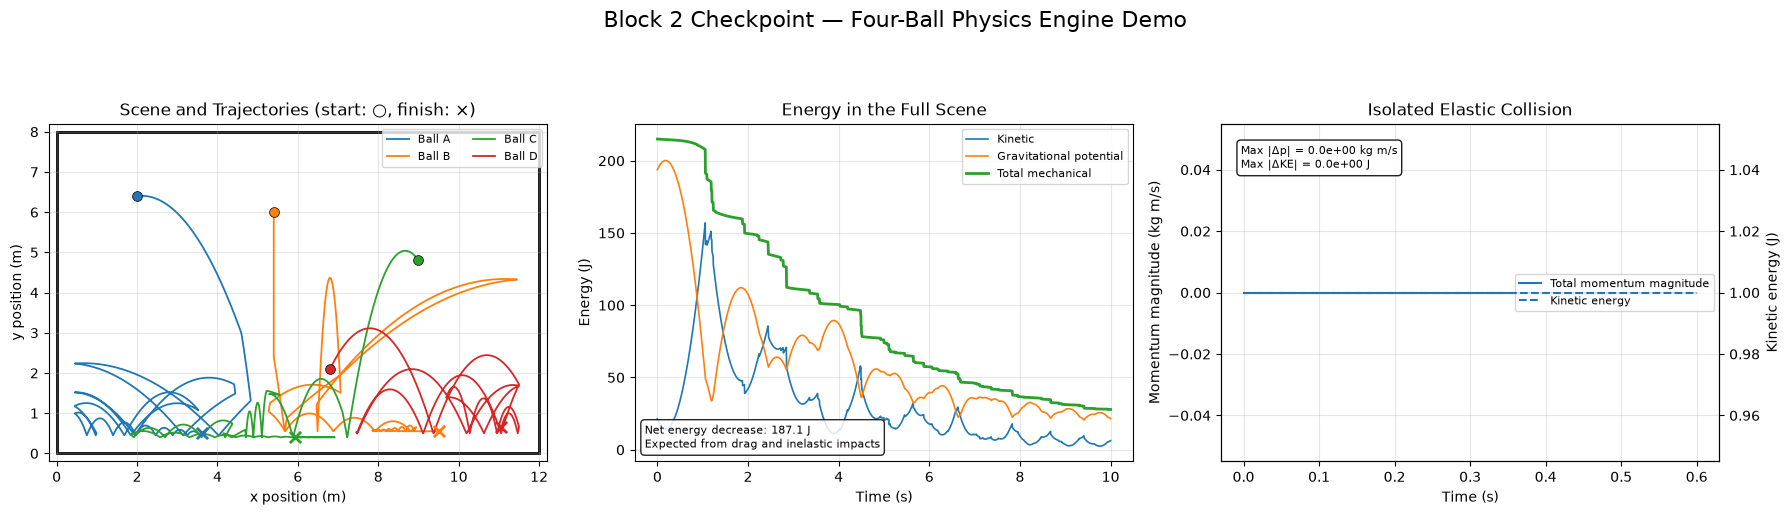

In [80]:
# Create the multi-panel figure sequence

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(
    "Block 2 Checkpoint — Four-Ball Physics Engine Demo",
    fontsize=16,
    y=1.02
)

# Panel 1: Four-ball trajectories
ax = axes[0]

xmin, xmax, ymin, ymax = bounds

ax.add_patch(
    Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        linewidth=2,
        edgecolor="black"
    )
)

for i, body in enumerate(demo_world.bodies):
    line, = ax.plot(
        positions[:, i, 0],
        positions[:, i, 1],
        label=body.name,
        linewidth=1.3
    )

    body_color = line.get_color()

    ax.scatter(
        positions[0, i, 0],
        positions[0, i, 1],
        marker="o",
        s=50,
        color=body_color,
        edgecolor="black",
        linewidth=0.5,
        zorder=4
    )

    ax.scatter(
        positions[-1, i, 0],
        positions[-1, i, 1],
        marker="x",
        s=65,
        color=body_color,
        linewidth=2,
        zorder=4
    )

ax.set_xlim(xmin - 0.2, xmax + 0.2)
ax.set_ylim(ymin - 0.2, ymax + 0.2)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x position (m)")
ax.set_ylabel("y position (m)")
ax.set_title("Scene and Trajectories (start: ○, finish: ×)")
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.3)

# Panel 2: Energy in the four-ball system
ax = axes[1]

ax.plot(t, kinetic_energy, label="Kinetic", linewidth=1.2)
ax.plot(
    t,
    potential_energy,
    label="Gravitational potential",
    linewidth=1.2
)
ax.plot(
    t,
    total_energy,
    label="Total mechanical",
    linewidth=2
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Energy (J)")
ax.set_title("Energy in the Full Scene")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax.text(
    0.02,
    0.03,
    f"Net energy decrease: {energy_loss:.1f} J\n"
    "Expected from drag and inelastic impacts",
    transform=ax.transAxes,
    fontsize=8,
    va="bottom",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        alpha=0.85
    )
)

# Panel 3: Isolated elastic collision conservation check
ax = axes[2]

lin_p, = ax.plot(
    t_elastic,
    np.linalg.norm(p_elastic, axis=1),
    label="Total momentum magnitude",
    linewidth=1.5
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Momentum magnitude (kg m/s)")
ax.set_title("Isolated Elastic Collision")
ax.grid(alpha=0.3)

# Second y-axis for kinetic energy
ax2 = ax.twinx()

lin_ke, = ax2.plot(
    t_elastic,
    ke_elastic,
    linestyle="--",
    label="Kinetic energy",
    linewidth=1.5
)

ax2.set_ylabel("Kinetic energy (J)")

ax.legend(
    [lin_p, lin_ke],
    [lin_p.get_label(), lin_ke.get_label()],
    loc="center right",
    fontsize=8
)

ax.text(
    0.04,
    0.94,
    f"Max |Δp| = {max_momentum_deviation:.1e} kg m/s\n"
    f"Max |ΔKE| = {max_ke_deviation:.1e} J",
    transform=ax.transAxes,
    fontsize=8,
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        alpha=0.88
    )
)

fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## Interpretation and architecture

- **Architecture:** `World` owns the four `Body` instances, the `Gravity` and `Drag` force objects, the `EulerCromer` integrator, collision handling, and simulation history. Each force adds to each body's force accumulator; the integrator updates the body state.
- **Full-simulation energy:** the net mechanical-energy decrease is physically expected because quadratic drag removes energy and the coefficient of restitution (`0.88`) makes collisions inelastic. Small additional numerical effects can come from the fixed timestep.
- **Full-simulation momentum:** it is not expected to remain constant because gravity and drag are external forces on the four-ball system, and wall collisions apply external impulses.
- **Conservation validation:** the separate isolated test has no gravity, drag, or walls and uses restitution `1.0`. In that case, linear momentum and kinetic energy remain constant through the equal-mass collision.